In [1]:
import sys
import os
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "models/nafnet")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("PyTorch version:", torch.__version__)

Using device: cuda
PyTorch version: 2.11.0+cu128


In [2]:
import sys
import os

# Remove any cached basicsr modules so we get a clean re-import
for mod_name in list(sys.modules.keys()):
    if mod_name.startswith("basicsr"):
        del sys.modules[mod_name]

# Insert the LOCAL nafnet repo's path at the very front, using an ABSOLUTE path
nafnet_path = os.path.abspath("models/nafnet")
if nafnet_path in sys.path:
    sys.path.remove(nafnet_path)
sys.path.insert(0, nafnet_path)

print("sys.path[0]:", sys.path[0])

import basicsr
print("basicsr now loaded from:", basicsr.__file__)

sys.path[0]: C:\Users\sidk4\work_Docs\UniversalImageRestoration\models\nafnet
basicsr now loaded from: None


In [3]:
from basicsr.models.archs.NAFNet_arch import NAFNetLocal
print("Import successful")

Import successful


In [4]:
print("Current working directory:", os.getcwd())
import basicsr
print("basicsr loaded from:", basicsr.__file__)

Current working directory: C:\Users\sidk4\work_Docs\UniversalImageRestoration
basicsr loaded from: None


In [5]:
from basicsr.models.archs.NAFNet_arch import NAFNetLocal

nafnet_gopro = NAFNetLocal(
    img_channel=3,
    width=64,
    middle_blk_num=1,
    enc_blk_nums=[1, 1, 1, 28],
    dec_blk_nums=[1, 1, 1, 1],
    train_size=(1, 3, 256, 256),
    fast_imp=False
)

ckpt = torch.load("checkpoints/nafnet_gopro.pth", map_location="cpu")
nafnet_gopro.load_state_dict(ckpt["params"], strict=True)
nafnet_gopro.eval()
nafnet_gopro = nafnet_gopro.to(device)

total_params = sum(p.numel() for p in nafnet_gopro.parameters())
print(f"NAFNet-GoPro loaded successfully. Total params: {total_params:,}")

NAFNet-GoPro loaded successfully. Total params: 67,888,835


Image shape (H, W, C): (375, 500, 3)


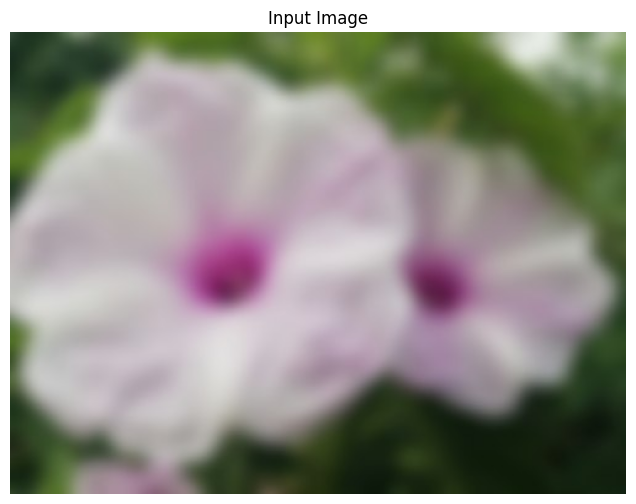

In [6]:
img_path = "blur-image.jpg"

img_bgr = cv2.imread(img_path)
if img_bgr is None:
    raise FileNotFoundError(f"Could not read {img_path} — check it exists in input/")

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
print("Image shape (H, W, C):", img_rgb.shape)

plt.figure(figsize=(8, 6))
plt.imshow(img_rgb)
plt.title("Input Image")
plt.axis("off")
plt.show()

Input tensor shape: torch.Size([1, 3, 375, 500])
Inference took 0.95 seconds
Saved to output/test1_nafnet_gopro.jpg


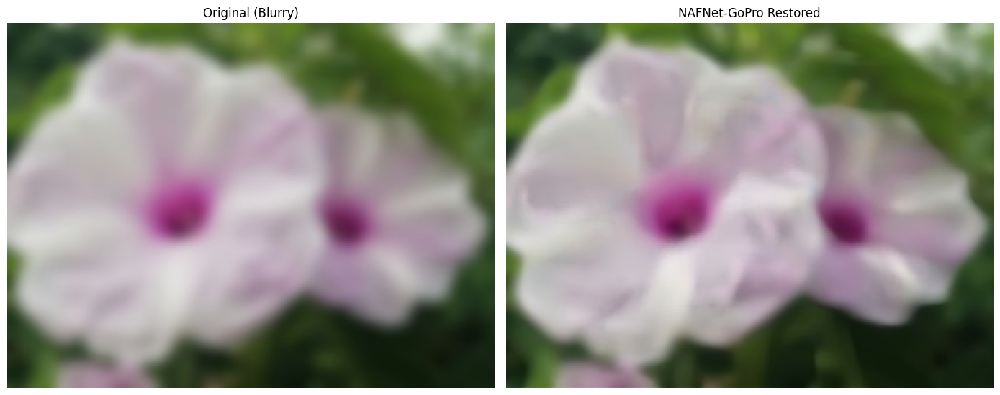

In [7]:
import time

img_norm = img_rgb.astype(np.float32) / 255.0
img_tensor = torch.from_numpy(img_norm).permute(2, 0, 1).unsqueeze(0).to(device)
print("Input tensor shape:", img_tensor.shape)

start = time.time()
with torch.no_grad():
    output_tensor = nafnet_gopro(img_tensor)
elapsed = time.time() - start
print(f"Inference took {elapsed:.2f} seconds")

output_np = output_tensor.clamp(0, 1).squeeze(0).permute(1, 2, 0).cpu().numpy()
output_img = (output_np * 255.0).round().astype(np.uint8)

os.makedirs("output", exist_ok=True)
output_bgr = cv2.cvtColor(output_img, cv2.COLOR_RGB2BGR)
cv2.imwrite("output/test1_nafnet_gopro.jpg", output_bgr)
print("Saved to output/test1_nafnet_gopro.jpg")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(img_rgb)
axes[0].set_title("Original (Blurry)")
axes[0].axis("off")
axes[1].imshow(output_img)
axes[1].set_title("NAFNet-GoPro Restored")
axes[1].axis("off")
plt.tight_layout()
plt.show()

In [8]:
ckpt_motion = torch.load("checkpoints/restormer_motion.pth", map_location="cpu")
print("Top-level keys:", list(ckpt_motion.keys()))

if "params" in ckpt_motion:
    sd = ckpt_motion["params"]
elif "state_dict" in ckpt_motion:
    sd = ckpt_motion["state_dict"]
else:
    sd = ckpt_motion

print("Number of weight tensors:", len(sd))
print("First 5 layer names:")
for i, k in enumerate(sd.keys()):
    if i >= 5:
        break
    print(" ", k)

Top-level keys: ['params']
Number of weight tensors: 494
First 5 layer names:
  patch_embed.proj.weight
  encoder_level1.0.norm1.body.weight
  encoder_level1.0.norm1.body.bias
  encoder_level1.0.attn.temperature
  encoder_level1.0.attn.qkv.weight


In [9]:
restormer_path = os.path.abspath("models/restormer")
if restormer_path not in sys.path:
    sys.path.insert(0, restormer_path)

# Clear any cached basicsr modules from the NAFNet import, so Restormer's own
# local basicsr copy gets picked up instead
for mod_name in list(sys.modules.keys()):
    if mod_name.startswith("basicsr"):
        del sys.modules[mod_name]

from basicsr.models.archs.restormer_arch import Restormer

def load_restormer(checkpoint_path):
    model = Restormer(
        inp_channels=3,
        out_channels=3,
        dim=48,
        num_blocks=[4, 6, 6, 8],
        num_refinement_blocks=4,
        heads=[1, 2, 4, 8],
        ffn_expansion_factor=2.66,
        bias=False,
        LayerNorm_type='WithBias',
        dual_pixel_task=False
    )
    ckpt = torch.load(checkpoint_path, map_location="cpu")
    model.load_state_dict(ckpt["params"], strict=True)
    model.eval()
    return model.to(device)

restormer_motion = load_restormer("checkpoints/restormer_motion.pth")
print("Restormer-Motion loaded. Params:", sum(p.numel() for p in restormer_motion.parameters()))

restormer_defocus = load_restormer("checkpoints/restormer_defocus.pth")
print("Restormer-Defocus loaded. Params:", sum(p.numel() for p in restormer_defocus.parameters()))

Restormer-Motion loaded. Params: 26126644
Restormer-Defocus loaded. Params: 26126644


Restormer-Motion inference: 0.89s
Restormer-Defocus inference: 0.60s
Saved both outputs


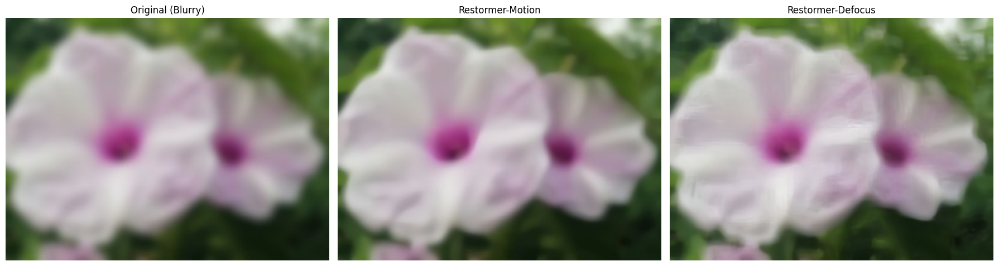

In [10]:
def restormer_infer(model, img_rgb, window_size=8):
    img_norm = img_rgb.astype(np.float32) / 255.0
    img_tensor = torch.from_numpy(img_norm).permute(2, 0, 1).unsqueeze(0).to(device)

    # Pad so H and W are multiples of window_size (Restormer requirement)
    _, _, h, w = img_tensor.shape
    pad_h = (window_size - h % window_size) % window_size
    pad_w = (window_size - w % window_size) % window_size
    img_padded = F.pad(img_tensor, (0, pad_w, 0, pad_h), mode='reflect')

    with torch.no_grad():
        output = model(img_padded)

    output = output[:, :, :h, :w]  # crop back to original size
    output_np = output.clamp(0, 1).squeeze(0).permute(1, 2, 0).cpu().numpy()
    return (output_np * 255.0).round().astype(np.uint8)

import torch.nn.functional as F
import time

start = time.time()
out_motion = restormer_infer(restormer_motion, img_rgb)
print(f"Restormer-Motion inference: {time.time()-start:.2f}s")

start = time.time()
out_defocus = restormer_infer(restormer_defocus, img_rgb)
print(f"Restormer-Defocus inference: {time.time()-start:.2f}s")

cv2.imwrite("output/test1_restormer_motion.jpg", cv2.cvtColor(out_motion, cv2.COLOR_RGB2BGR))
cv2.imwrite("output/test1_restormer_defocus.jpg", cv2.cvtColor(out_defocus, cv2.COLOR_RGB2BGR))
print("Saved both outputs")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(img_rgb)
axes[0].set_title("Original (Blurry)")
axes[0].axis("off")
axes[1].imshow(out_motion)
axes[1].set_title("Restormer-Motion")
axes[1].axis("off")
axes[2].imshow(out_defocus)
axes[2].set_title("Restormer-Defocus")
axes[2].axis("off")
plt.tight_layout()
plt.show()

In [11]:
ckpt_mprnet = torch.load("checkpoints/mprnet_deblurring.pth", map_location="cpu")
print("Top-level keys:", list(ckpt_mprnet.keys()))

sd = ckpt_mprnet["state_dict"]
print("Number of weight tensors:", len(sd))
print("First 5 layer names:")
for i, k in enumerate(sd.keys()):
    if i >= 5:
        break
    print(" ", k)

Top-level keys: ['state_dict']
Number of weight tensors: 316
First 5 layer names:
  shallow_feat3.0.weight
  shallow_feat3.1.CA.conv_du.0.weight
  shallow_feat3.1.CA.conv_du.2.weight
  shallow_feat3.1.body.0.weight
  shallow_feat3.1.body.1.weight


In [12]:
mprnet_path = os.path.abspath("models/mprnet/Deblurring")
if mprnet_path not in sys.path:
    sys.path.insert(0, mprnet_path)

from MPRNet import MPRNet

def load_mprnet(checkpoint_path):
    model = MPRNet()  # defaults match the trained deblurring config
    ckpt = torch.load(checkpoint_path, map_location="cpu")
    model.load_state_dict(ckpt["state_dict"], strict=True)
    model.eval()
    return model.to(device)

mprnet_deblur = load_mprnet("checkpoints/mprnet_deblurring.pth")
print("MPRNet loaded. Params:", sum(p.numel() for p in mprnet_deblur.parameters()))

MPRNet loaded. Params: 20127073


MPRNet inference: 0.85s
Saved output/test1_mprnet.jpg


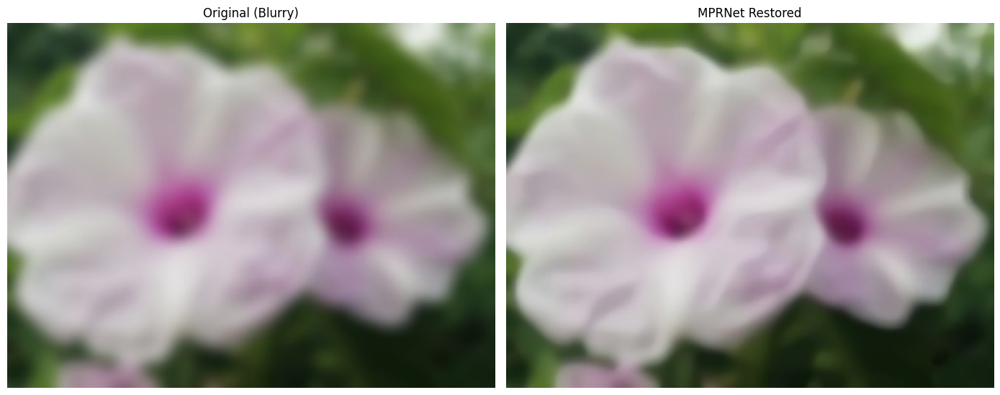

In [13]:
def mprnet_infer(model, img_rgb, factor=8):
    img_norm = img_rgb.astype(np.float32) / 255.0
    img_tensor = torch.from_numpy(img_norm).permute(2, 0, 1).unsqueeze(0).to(device)

    h, w = img_tensor.shape[2], img_tensor.shape[3]
    H, W = ((h + factor) // factor) * factor, ((w + factor) // factor) * factor
    padh = H - h if h % factor != 0 else 0
    padw = W - w if w % factor != 0 else 0
    img_padded = F.pad(img_tensor, (0, padw, 0, padh), mode='reflect')

    with torch.no_grad():
        restored = model(img_padded)

    output = torch.clamp(restored[0], 0, 1)
    output = output[:, :, :h, :w]  # crop back to original size

    output_np = output.squeeze(0).permute(1, 2, 0).cpu().numpy()
    return (output_np * 255.0).round().astype(np.uint8)

start = time.time()
out_mprnet = mprnet_infer(mprnet_deblur, img_rgb)
print(f"MPRNet inference: {time.time()-start:.2f}s")

cv2.imwrite("output/test1_mprnet.jpg", cv2.cvtColor(out_mprnet, cv2.COLOR_RGB2BGR))
print("Saved output/test1_mprnet.jpg")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(img_rgb)
axes[0].set_title("Original (Blurry)")
axes[0].axis("off")
axes[1].imshow(out_mprnet)
axes[1].set_title("MPRNet Restored")
axes[1].axis("off")
plt.tight_layout()
plt.show()

In [14]:
import glob

input_files = sorted(glob.glob("input/*.jpg") + glob.glob("input/*.png") + glob.glob("input/*.jpeg"))
print(f"Found {len(input_files)} images in input/:")
for f in input_files:
    print(" ", f)

Found 5 images in input/:
  input\eiffel_defocus.jpg
  input\eiffel_handheld.jpg
  input\eiffel_mixed.jpg
  input\eiffel_motion.jpg
  input\eiffel_sharp.jpg


In [15]:
def load_image_rgb(path):
    img_bgr = cv2.imread(path)
    if img_bgr is None:
        raise FileNotFoundError(f"Could not read {path}")
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

def nafnet_infer(model, img_rgb):
    img_norm = img_rgb.astype(np.float32) / 255.0
    img_tensor = torch.from_numpy(img_norm).permute(2, 0, 1).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(img_tensor)
    output_np = output.clamp(0, 1).squeeze(0).permute(1, 2, 0).cpu().numpy()
    return (output_np * 255.0).round().astype(np.uint8)

MODELS = {
    "NAFNet-GoPro": lambda img: nafnet_infer(nafnet_gopro, img),
    "Restormer-Motion": lambda img: restormer_infer(restormer_motion, img),
    "Restormer-Defocus": lambda img: restormer_infer(restormer_defocus, img),
    "MPRNet": lambda img: mprnet_infer(mprnet_deblur, img),
}

print("Registered models:", list(MODELS.keys()))

Registered models: ['NAFNet-GoPro', 'Restormer-Motion', 'Restormer-Defocus', 'MPRNet']


In [16]:
import os

os.makedirs("output", exist_ok=True)
os.makedirs("comparisons", exist_ok=True)

results = {}  # results[image_name][model_name] = restored image array

for img_path in input_files:
    img_name = os.path.splitext(os.path.basename(img_path))[0]
    print(f"\n=== Processing {img_name} ===")

    img_rgb = load_image_rgb(img_path)
    results[img_name] = {"original": img_rgb}

    for model_name, infer_fn in MODELS.items():
        start = time.time()
        try:
            restored = infer_fn(img_rgb)
            elapsed = time.time() - start
            results[img_name][model_name] = restored

            out_path = f"output/{img_name}_{model_name.replace('-', '_')}.jpg"
            cv2.imwrite(out_path, cv2.cvtColor(restored, cv2.COLOR_RGB2BGR))
            print(f"  {model_name}: {elapsed:.2f}s -> saved {out_path}")
        except Exception as e:
            print(f"  {model_name}: FAILED - {e}")
            results[img_name][model_name] = None

print("\nAll processing complete.")


=== Processing eiffel_defocus ===
  NAFNet-GoPro: 0.19s -> saved output/eiffel_defocus_NAFNet_GoPro.jpg
  Restormer-Motion: 0.58s -> saved output/eiffel_defocus_Restormer_Motion.jpg
  Restormer-Defocus: 0.58s -> saved output/eiffel_defocus_Restormer_Defocus.jpg
  MPRNet: 0.67s -> saved output/eiffel_defocus_MPRNet.jpg

=== Processing eiffel_handheld ===
  NAFNet-GoPro: 0.18s -> saved output/eiffel_handheld_NAFNet_GoPro.jpg
  Restormer-Motion: 0.58s -> saved output/eiffel_handheld_Restormer_Motion.jpg
  Restormer-Defocus: 0.58s -> saved output/eiffel_handheld_Restormer_Defocus.jpg
  MPRNet: 0.66s -> saved output/eiffel_handheld_MPRNet.jpg

=== Processing eiffel_mixed ===
  NAFNet-GoPro: 0.19s -> saved output/eiffel_mixed_NAFNet_GoPro.jpg
  Restormer-Motion: 0.58s -> saved output/eiffel_mixed_Restormer_Motion.jpg
  Restormer-Defocus: 0.58s -> saved output/eiffel_mixed_Restormer_Defocus.jpg
  MPRNet: 0.66s -> saved output/eiffel_mixed_MPRNet.jpg

=== Processing eiffel_motion ===
  NAFNet

Saved comparisons/eiffel_defocus_comparison.jpg


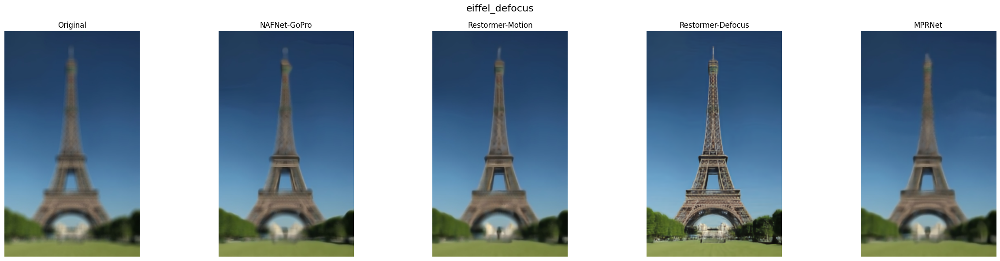

Saved comparisons/eiffel_handheld_comparison.jpg


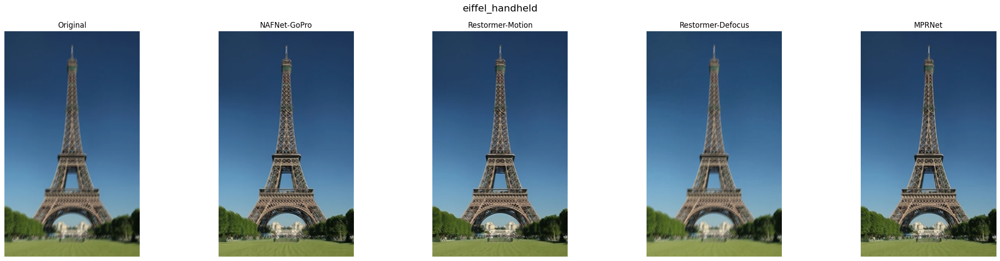

Saved comparisons/eiffel_mixed_comparison.jpg


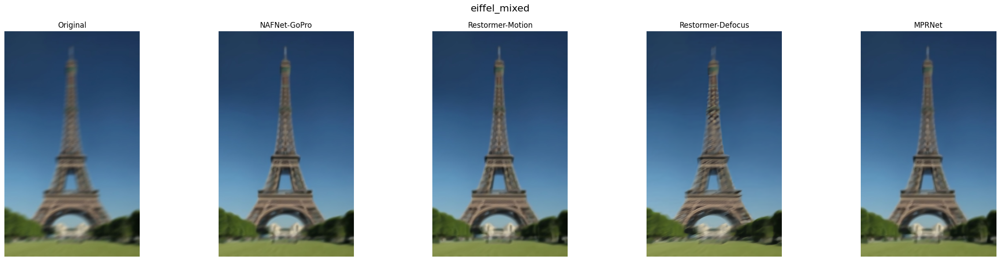

Saved comparisons/eiffel_motion_comparison.jpg


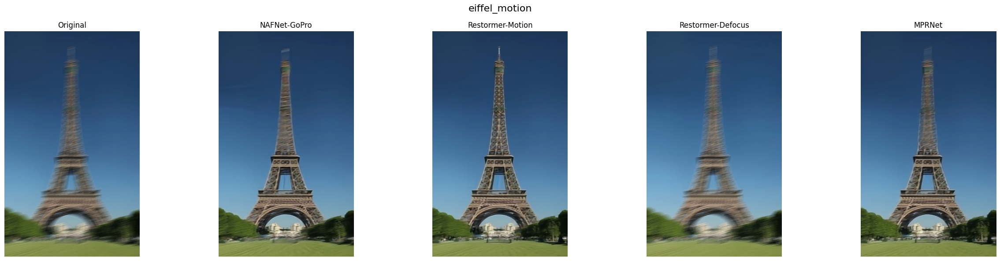

Saved comparisons/eiffel_sharp_comparison.jpg


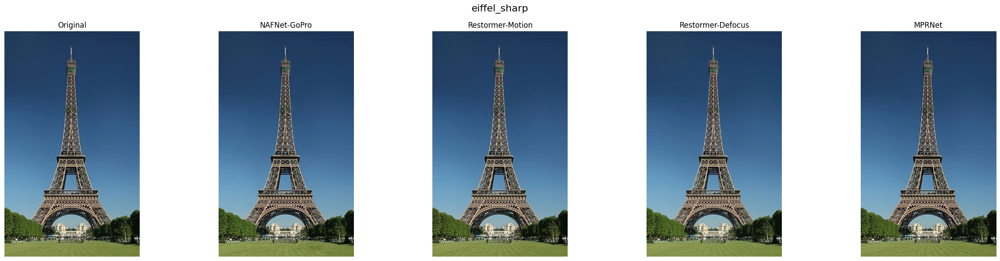

In [17]:
def build_comparison_grid(img_name, results_dict, model_names):
    n_cols = len(model_names) + 1  # +1 for original
    fig, axes = plt.subplots(1, n_cols, figsize=(5 * n_cols, 6))

    axes[0].imshow(results_dict["original"])
    axes[0].set_title("Original")
    axes[0].axis("off")

    for i, model_name in enumerate(model_names, start=1):
        restored = results_dict.get(model_name)
        if restored is not None:
            axes[i].imshow(restored)
            axes[i].set_title(model_name)
        else:
            axes[i].text(0.5, 0.5, "FAILED", ha="center", va="center")
        axes[i].axis("off")

    plt.suptitle(img_name, fontsize=16)
    plt.tight_layout()

    save_path = f"comparisons/{img_name}_comparison.jpg"
    plt.savefig(save_path, dpi=100, bbox_inches="tight")
    print(f"Saved {save_path}")
    plt.show()

model_names = list(MODELS.keys())
for img_name in results:
    build_comparison_grid(img_name, results[img_name], model_names)

In [18]:
for img_path in input_files:
    img = cv2.imread(img_path)
    print(img_path, "->", img.shape)

input\eiffel_defocus.jpg -> (550, 330, 3)
input\eiffel_handheld.jpg -> (550, 330, 3)
input\eiffel_mixed.jpg -> (550, 330, 3)
input\eiffel_motion.jpg -> (550, 330, 3)
input\eiffel_sharp.jpg -> (550, 330, 3)


In [19]:
def tiled_inference(model_fn, img_tensor, tile_size=512, tile_overlap=32, multiple_of=8):
    """
    model_fn: a function that takes a padded tensor (B,C,H,W) and returns a tensor of the same shape
    img_tensor: input tensor (B,C,H,W), values in [0,1], NOT yet padded
    """
    b, c, h, w = img_tensor.shape

    # If image is already smaller than tile size in both dims, no need to tile
    if h <= tile_size and w <= tile_size:
        H = ((h + multiple_of) // multiple_of) * multiple_of
        W = ((w + multiple_of) // multiple_of) * multiple_of
        padh = H - h if h % multiple_of != 0 else 0
        padw = W - w if w % multiple_of != 0 else 0
        padded = F.pad(img_tensor, (0, padw, 0, padh), mode='reflect')
        with torch.no_grad():
            out = model_fn(padded)
        return out[:, :, :h, :w].clamp(0, 1)

    # Pad full image to multiple_of first
    H = ((h + multiple_of) // multiple_of) * multiple_of
    W = ((w + multiple_of) // multiple_of) * multiple_of
    padh = H - h if h % multiple_of != 0 else 0
    padw = W - w if w % multiple_of != 0 else 0
    input_padded = F.pad(img_tensor, (0, padw, 0, padh), mode='reflect')

    _, _, H, W = input_padded.shape
    tile = min(tile_size, H, W)
    # Ensure tile is a multiple of our padding requirement
    tile = (tile // multiple_of) * multiple_of
    stride = tile - tile_overlap

    h_idx_list = list(range(0, H - tile, stride)) + [H - tile]
    w_idx_list = list(range(0, W - tile, stride)) + [W - tile]

    E = torch.zeros(b, c, H, W, device=img_tensor.device)
    W_acc = torch.zeros_like(E)

    with torch.no_grad():
        for h_idx in h_idx_list:
            for w_idx in w_idx_list:
                in_patch = input_padded[..., h_idx:h_idx+tile, w_idx:w_idx+tile]
                out_patch = model_fn(in_patch)
                E[..., h_idx:h_idx+tile, w_idx:w_idx+tile] += out_patch
                W_acc[..., h_idx:h_idx+tile, w_idx:w_idx+tile] += 1

    restored = E / W_acc
    restored = restored[:, :, :h, :w]
    return restored.clamp(0, 1)

print("Tiled inference wrapper defined")

Tiled inference wrapper defined


In [20]:
def nafnet_model_fn(tensor):
    return nafnet_gopro(tensor)

def restormer_motion_model_fn(tensor):
    return restormer_motion(tensor)

def restormer_defocus_model_fn(tensor):
    return restormer_defocus(tensor)

def mprnet_model_fn(tensor):
    # MPRNet returns a list [stage3_img, stage2_img, stage1_img] — we only want stage3 (final, best quality)
    return mprnet_deblur(tensor)[0]

def run_model_tiled(model_fn, img_rgb, multiple_of, tile_size=512, tile_overlap=32):
    img_norm = img_rgb.astype(np.float32) / 255.0
    img_tensor = torch.from_numpy(img_norm).permute(2, 0, 1).unsqueeze(0).to(device)

    output = tiled_inference(model_fn, img_tensor, tile_size=tile_size, tile_overlap=tile_overlap, multiple_of=multiple_of)

    output_np = output.squeeze(0).permute(1, 2, 0).cpu().numpy()
    return (output_np * 255.0).round().astype(np.uint8)

# Rebuild the MODELS dictionary to use tiled inference for every model
MODELS = {
    "NAFNet-GoPro": lambda img: run_model_tiled(nafnet_model_fn, img, multiple_of=16),
    "Restormer-Motion": lambda img: run_model_tiled(restormer_motion_model_fn, img, multiple_of=8),
    "Restormer-Defocus": lambda img: run_model_tiled(restormer_defocus_model_fn, img, multiple_of=8),
    "MPRNet": lambda img: run_model_tiled(mprnet_model_fn, img, multiple_of=8),
}

print("Rebuilt MODELS dict with tiled inference:", list(MODELS.keys()))

Rebuilt MODELS dict with tiled inference: ['NAFNet-GoPro', 'Restormer-Motion', 'Restormer-Defocus', 'MPRNet']


In [21]:
results = {}

for img_path in input_files:
    img_name = os.path.splitext(os.path.basename(img_path))[0]
    print(f"\n=== Processing {img_name} ===")
    img_rgb = load_image_rgb(img_path)
    results[img_name] = {"original": img_rgb}

    for model_name, infer_fn in MODELS.items():
        start = time.time()
        try:
            restored = infer_fn(img_rgb)
            elapsed = time.time() - start
            results[img_name][model_name] = restored
            out_path = f"output/{img_name}_{model_name.replace('-', '_')}_tiled.jpg"
            cv2.imwrite(out_path, cv2.cvtColor(restored, cv2.COLOR_RGB2BGR))
            print(f"  {model_name}: {elapsed:.2f}s -> saved {out_path}")
        except Exception as e:
            print(f"  {model_name}: FAILED - {e}")
            results[img_name][model_name] = None

print("\nDone.")


=== Processing eiffel_defocus ===
  NAFNet-GoPro: 0.52s -> saved output/eiffel_defocus_NAFNet_GoPro_tiled.jpg
  Restormer-Motion: 0.70s -> saved output/eiffel_defocus_Restormer_Motion_tiled.jpg
  Restormer-Defocus: 0.69s -> saved output/eiffel_defocus_Restormer_Defocus_tiled.jpg
  MPRNet: 0.86s -> saved output/eiffel_defocus_MPRNet_tiled.jpg

=== Processing eiffel_handheld ===
  NAFNet-GoPro: 0.20s -> saved output/eiffel_handheld_NAFNet_GoPro_tiled.jpg
  Restormer-Motion: 0.69s -> saved output/eiffel_handheld_Restormer_Motion_tiled.jpg
  Restormer-Defocus: 0.68s -> saved output/eiffel_handheld_Restormer_Defocus_tiled.jpg
  MPRNet: 0.82s -> saved output/eiffel_handheld_MPRNet_tiled.jpg

=== Processing eiffel_mixed ===
  NAFNet-GoPro: 0.17s -> saved output/eiffel_mixed_NAFNet_GoPro_tiled.jpg
  Restormer-Motion: 0.68s -> saved output/eiffel_mixed_Restormer_Motion_tiled.jpg
  Restormer-Defocus: 0.69s -> saved output/eiffel_mixed_Restormer_Defocus_tiled.jpg
  MPRNet: 0.83s -> saved output/

In [26]:
input_files = sorted(glob.glob("input/*.jpg") + glob.glob("input/*.png") + glob.glob("input/*.jpeg"))
print(f"Found {len(input_files)} images in input/:")
for f in input_files:
    print(" ", f)

Found 5 images in input/:
  input\eiffel_defocus.jpg
  input\eiffel_handheld.jpg
  input\eiffel_mixed.jpg
  input\eiffel_motion.jpg
  input\eiffel_sharp.jpg


In [27]:
results = {}
start_total = time.time()

for img_path in input_files:
    img_name = os.path.splitext(os.path.basename(img_path))[0]
    img_rgb = load_image_rgb(img_path)
    print(f"\n=== {img_name} (shape: {img_rgb.shape}) ===")
    results[img_name] = {"original": img_rgb}

    for model_name, infer_fn in MODELS.items():
        start = time.time()
        try:
            restored = infer_fn(img_rgb)
            elapsed = time.time() - start
            results[img_name][model_name] = restored
            out_path = f"output/{img_name}_{model_name.replace('-', '_')}.jpg"
            cv2.imwrite(out_path, cv2.cvtColor(restored, cv2.COLOR_RGB2BGR))
            print(f"  {model_name}: {elapsed:.2f}s")
        except Exception as e:
            print(f"  {model_name}: FAILED - {e}")
            results[img_name][model_name] = None

print(f"\nTotal: {time.time()-start_total:.2f}s")


=== eiffel_defocus (shape: (550, 330, 3)) ===
  NAFNet-GoPro: 0.58s
  Restormer-Motion: 0.68s
  Restormer-Defocus: 0.68s
  MPRNet: 0.82s

=== eiffel_handheld (shape: (550, 330, 3)) ===
  NAFNet-GoPro: 0.18s
  Restormer-Motion: 0.68s
  Restormer-Defocus: 0.68s
  MPRNet: 0.82s

=== eiffel_mixed (shape: (550, 330, 3)) ===
  NAFNet-GoPro: 0.19s
  Restormer-Motion: 0.69s
  Restormer-Defocus: 0.69s
  MPRNet: 0.82s

=== eiffel_motion (shape: (550, 330, 3)) ===
  NAFNet-GoPro: 0.17s
  Restormer-Motion: 0.68s
  Restormer-Defocus: 0.68s
  MPRNet: 0.82s

=== eiffel_sharp (shape: (550, 330, 3)) ===
  NAFNet-GoPro: 0.17s
  Restormer-Motion: 0.68s
  Restormer-Defocus: 0.68s
  MPRNet: 0.85s

Total: 12.33s


In [28]:
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

ground_truth = results["eiffel_sharp"]["original"]

blur_test_images = ["eiffel_motion", "eiffel_defocus", "eiffel_handheld", "eiffel_mixed"]
model_names = list(MODELS.keys())

print(f"{'Image':<18}{'Model':<20}{'PSNR (dB)':<12}{'SSIM':<8}")
print("-" * 58)

scores = {}
for img_name in blur_test_images:
    if img_name not in results:
        continue

    # Score of the blurry input itself, as a baseline reference
    blurry_input = results[img_name]["original"]
    baseline_psnr = psnr(ground_truth, blurry_input)
    baseline_ssim = ssim(ground_truth, blurry_input, channel_axis=2)
    print(f"{img_name:<18}{'(blurry input)':<20}{baseline_psnr:<12.2f}{baseline_ssim:<8.4f}")

    scores[img_name] = {}
    for model_name in model_names:
        restored = results[img_name].get(model_name)
        if restored is None:
            continue
        p = psnr(ground_truth, restored)
        s = ssim(ground_truth, restored, channel_axis=2)
        scores[img_name][model_name] = {"psnr": p, "ssim": s}
        print(f"{'':<18}{model_name:<20}{p:<12.2f}{s:<8.4f}")
    print()

Image             Model               PSNR (dB)   SSIM    
----------------------------------------------------------
eiffel_motion     (blurry input)      20.65       0.7450  
                  NAFNet-GoPro        22.74       0.8363  
                  Restormer-Motion    22.91       0.8424  
                  Restormer-Defocus   19.95       0.7395  
                  MPRNet              22.39       0.8246  

eiffel_defocus    (blurry input)      20.31       0.7194  
                  NAFNet-GoPro        20.50       0.7338  
                  Restormer-Motion    20.70       0.7443  
                  Restormer-Defocus   21.11       0.8048  
                  MPRNet              20.63       0.7412  

eiffel_handheld   (blurry input)      20.33       0.7545  
                  NAFNet-GoPro        18.74       0.7088  
                  Restormer-Motion    18.92       0.7178  
                  Restormer-Defocus   19.59       0.7423  
                  MPRNet              18.97       0.71

Saved comparisons/eiffel_motion_comparison.jpg


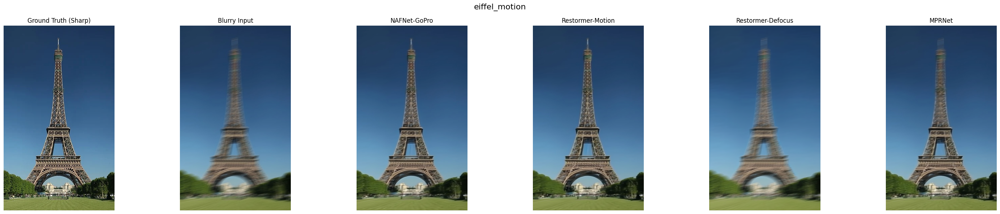

Saved comparisons/eiffel_defocus_comparison.jpg


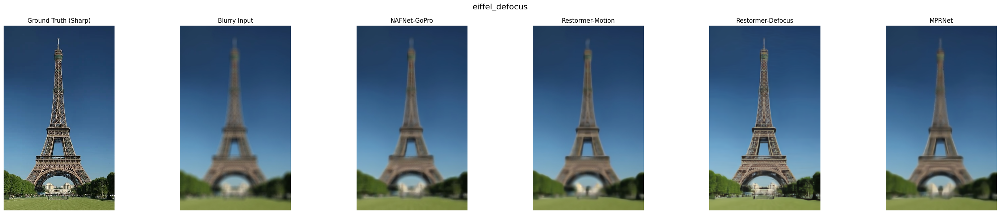

Saved comparisons/eiffel_handheld_comparison.jpg


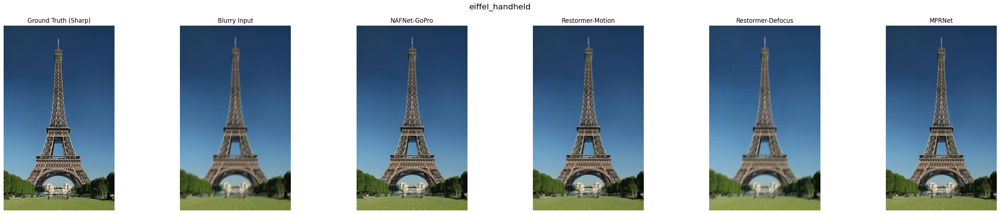

Saved comparisons/eiffel_mixed_comparison.jpg


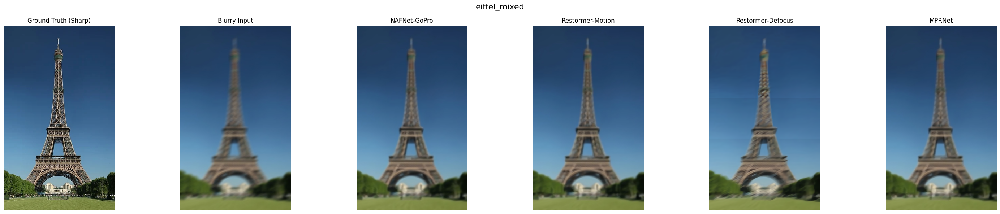

In [30]:
def build_comparison_grid_with_gt(img_name, ground_truth, results_dict, model_names):
    n_cols = len(model_names) + 2  # +1 for blurry input, +1 for ground truth
    fig, axes = plt.subplots(1, n_cols, figsize=(5 * n_cols, 6))

    axes[0].imshow(ground_truth)
    axes[0].set_title("Ground Truth (Sharp)")
    axes[0].axis("off")

    axes[1].imshow(results_dict["original"])
    axes[1].set_title("Blurry Input")
    axes[1].axis("off")

    for i, model_name in enumerate(model_names, start=2):
        restored = results_dict.get(model_name)
        if restored is not None:
            axes[i].imshow(restored)
            axes[i].set_title(model_name)
        else:
            axes[i].text(0.5, 0.5, "FAILED", ha="center", va="center")
        axes[i].axis("off")

    plt.suptitle(img_name, fontsize=16)
    plt.tight_layout()

    save_path = f"comparisons/{img_name}_comparison.jpg"
    plt.savefig(save_path, dpi=100, bbox_inches="tight")
    print(f"Saved {save_path}")
    plt.show()

ground_truth = results["eiffel_sharp"]["original"]
model_names = list(MODELS.keys())

for img_name in ["eiffel_motion", "eiffel_defocus", "eiffel_handheld", "eiffel_mixed"]:
    build_comparison_grid_with_gt(img_name, ground_truth, results[img_name], model_names)

In [31]:
from PIL import Image

def load_image_universal(path):
    """Robust loader: tries OpenCV first, falls back to PIL for formats cv2 struggles with (webp, some PNGs, etc.)"""
    img_bgr = cv2.imread(path)
    if img_bgr is not None:
        return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # Fallback: PIL handles a wider range of formats (webp, heic-with-plugin, etc.)
    try:
        pil_img = Image.open(path).convert("RGB")
        return np.array(pil_img)
    except Exception as e:
        raise FileNotFoundError(f"Could not read {path} with either OpenCV or PIL: {e}")

# Quick test — should work regardless of format
test_img = load_image_universal("input/eiffel_sharp.jpg")
print("Universal loader test:", test_img.shape)

Universal loader test: (550, 330, 3)


In [35]:
pip install pyiqa

  Using cached pyiqa-0.1.16-py3-none-any.whl.metadata (20 kB)
  Using cached accelerate-1.14.0-py3-none-any.whl.metadata (19 kB)
  Using cached datasets-5.0.1-py3-none-any.whl.metadata (23 kB)
  Using cached bitsandbytes-0.50.0-py3-none-win_amd64.whl.metadata (10 kB)
  Using cached facexlib-0.3.0-py3-none-any.whl.metadata (4.6 kB)
  Using cached openai_clip-1.0.1-py3-none-any.whl
  Using cached opencv_python_headless-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached pandas-2.3.3-cp310-cp310-win_amd64.whl.metadata (19 kB)
  Using cached pre_commit-4.6.1-py2.py3-none-any.whl.metadata (1.2 kB)
  Using cached pytest-9.1.1-py3-none-any.whl.metadata (7.6 kB)
  Using cached tensorboard-2.21.0-py3-none-any.whl.metadata (1.8 kB)
  Using cached timm-1.0.28-py3-none-any.whl.metadata (40 kB)
  Using cached transformers-5.14.1-py3-none-any.whl.metadata (32 kB)
  Using cached huggingface_hub-1.26.0-py3-none-any.whl.metadata (16 kB)
  Using cached tokenizers-0.22.2-cp39-abi3-win_amd64.

ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'C:\\Users\\sidk4\\.conda\\envs\\restore\\Lib\\site-packages\\cv2\\cv2.pyd'
Consider using the `--user` option or check the permissions.



In [34]:
import pyiqa

niqe_metric = pyiqa.create_metric('niqe', device=device)
brisque_metric = pyiqa.create_metric('brisque', device=device)
musiq_metric = pyiqa.create_metric('musiq', device=device)

print("NIQE lower_better:", niqe_metric.lower_better)
print("BRISQUE lower_better:", brisque_metric.lower_better)
print("MUSIQ lower_better:", musiq_metric.lower_better)

ModuleNotFoundError: No module named 'pyiqa'